# Experiment 7: Dog Breed Classification using Transfer Learning

---

## Problem Statement:
Develop an image classifier to identify dog breeds using pre-trained CNN architectures.

## Activities:
*   Use VGG16, ResNet, or MobileNet.
*   Fine-tune pre-trained model.
*   Evaluate classification accuracy.

### 1. Environment Setup

### Theory
This experiment employs **transfer learning**, a machine learning technique that re-uses a pre-trained model as a starting point for a new task. Instead of training a model from scratch, we leverage a model that has already learned general features from a vast dataset (like ImageNet).

**Key aspects of transfer learning in this context include:**

1.  **Feature Extraction:** Early layers of pre-trained Convolutional Neural Networks (CNNs) (e.g., VGG16, ResNet50, MobileNetV2) extract fundamental features like edges and textures, which are often universal.
2.  **Model Freezing:** We 'freeze' the weights of these early layers to preserve their general feature extraction capabilities during training.
3.  **Custom Classification Head:** New, trainable layers (e.g., `Flatten`, `Dense`, `Dropout`) are added on top of the frozen base model. These layers are trained to interpret the high-level features and map them to our specific dog breed classes, typically using a `softmax` activation for probabilities.
4.  **Data Augmentation:** To mitigate overfitting and effectively increase the training data size, **data augmentation** techniques (e.g., rotation, shifting, zooming) are applied to existing images.
5.  **Fine-tuning (Optional):** After initial training, unfreezing some later layers of the base model and continuing training with a low learning rate allows for fine-tuning of more abstract features, adapting the model further to the new dataset for potentially higher accuracy.

This approach effectively utilizes the knowledge embedded in state-of-the-art CNN architectures, enabling robust image classifiers with less data and training time.

In [ ]:
#23070521013 Amritansh Singh
import sys

# Install required libraries
!{sys.executable} -m pip install tensorflow matplotlib scikit-learn

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

---

### 2. Data Loading and Preparation

In [ ]:
# This cell sets up a dummy dataset structure for demonstration purposes.
# In a real scenario, replace this with your actual dog breed dataset.

print("Please upload your dog breed dataset or specify a path to an existing dataset.")
print("For example, you can use the 'Stanford Dogs Dataset' or 'Dogs vs Cats' dataset.")
print("Make sure your dataset is organized into subdirectories by breed for easy loading.")

dataset_path = 'dog_breed_dataset'

# Create dummy directories and files if they don't exist
if not os.path.exists(dataset_path):
    os.makedirs(os.path.join(dataset_path, 'train', 'breed1'))
    os.makedirs(os.path.join(dataset_path, 'train', 'breed2'))
    os.makedirs(os.path.join(dataset_path, 'validation', 'breed1'))
    os.makedirs(os.path.join(dataset_path, 'validation', 'breed2'))
    os.makedirs(os.path.join(dataset_path, 'test', 'breed1'))
    os.makedirs(os.path.join(dataset_path, 'test', 'breed2'))

    from PIL import Image
    img = Image.new('RGB', (224, 224), color = 'red')
    img.save(os.path.join(dataset_path, 'train', 'breed1', 'dog1.jpg'))
    img.save(os.path.join(dataset_path, 'train', 'breed2', 'dog2.jpg'))
    img.save(os.path.join(dataset_path, 'validation', 'breed1', 'dog3.jpg'))
    img.save(os.path.join(dataset_path, 'test', 'breed2', 'dog4.jpg'))
    print(f"Dummy dataset structure created at '{dataset_path}' for demonstration.")
else:
    print(f"Dataset path '{dataset_path}' already exists.")

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Data augmentation and preprocessing
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

validation_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load datasets using flow_from_directory
train_generator = train_datagen.flow_from_directory(
    os.path.join(dataset_path, 'train'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

validation_generator = validation_datagen.flow_from_directory(
    os.path.join(dataset_path, 'validation'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    os.path.join(dataset_path, 'test'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("Data generators created successfully.")

Please upload your dog breed dataset or specify a path to an existing dataset.
For example, you can use the 'Stanford Dogs Dataset' or 'Dogs vs Cats' dataset.
Make sure your dataset is organized into subdirectories by breed for easy loading.
Dataset path 'dog_breed_dataset' already exists.
Found 2 images belonging to 2 classes.
Found 1 images belonging to 2 classes.
Found 1 images belonging to 2 classes.
Data generators created successfully.


---

### 3. Model Selection and Loading

In [ ]:
# Determine the number of classes from the training generator
num_classes = train_generator.num_classes
print(f"Number of classes: {num_classes}")

def build_transfer_learning_model(base_model_name, input_shape, num_classes):
    """Builds a transfer learning model using a specified pre-trained base model."""

    if base_model_name == 'VGG16':
        base_model = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    elif base_model_name == 'ResNet50':
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    elif base_model_name == 'MobileNetV2':
        base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    else:
        raise ValueError("Unsupported base model name. Choose from 'VGG16', 'ResNet50', 'MobileNetV2'.")

    # Freeze the base model layers
    base_model.trainable = False

    # Add custom layers on top of the base model
    x = base_model.output
    x = Flatten()(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x)
    predictions = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=predictions)

    # Compile the model
    model.compile(optimizer=Adam(learning_rate=0.0001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    return model

# Choose a base model and build the full model
# Let's start with VGG16 as it's a common and effective choice for transfer learning.
model_name = 'VGG16'
input_shape = IMAGE_SIZE + (3,) # Add channel dimension

model = build_transfer_learning_model(model_name, input_shape, num_classes)

model.summary()
print(f"Model built using {model_name} as the base.")

Number of classes: 2
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,561,282 (105.14 MB)

 Trainable params: 12,846,594 (49.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Model built using VGG16 as the base.


---

### 4. Model Training (Fine-tuning)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Define callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('best_dog_breed_model.keras', save_best_only=True, monitor='val_accuracy', mode='max')

# Train the model
history = model.fit(
    train_generator,
    epochs=20, # You might need to adjust this based on dataset size and convergence
    validation_data=validation_generator,
    callbacks=[early_stopping, model_checkpoint]
)

print("Model training complete.")

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - accuracy: 0.5000 - loss: 1.1842 - val_accuracy: 0.0000e+00 - val_loss: 0.9405
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step - accuracy: 0.5000 - loss: 1.0185 - val_accuracy: 1.0000 - val_loss: 0.2805
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 1.0000 - loss: 0.4076 - val_accuracy: 1.0000 - val_loss: 0.1238
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 1.2718 - val_accuracy: 1.0000 - val_loss: 0.1204
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 1.4247 - val_accuracy: 1.0000 - val_loss: 0.2138
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 1.5762 - val_accuracy: 1.0000 - val_loss: 0.4515
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 0.5137 - val_accuracy: 1.0000 - val_loss: 0.6133
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 0.4329 - val_accuracy: 0.0000e+00 - val_loss: 0.9598
Epoch 9/

---

### 5. Model Evaluation

Evaluating model on test data...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 630ms/step - accuracy: 0.0000e+00 - loss: 2.1769
Test Loss: 2.1769
Test Accuracy: 0.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 945ms/step

Classification Report:
              precision    recall  f1-score   support

      breed1       0.00      0.00      0.00       0.0
      breed2       0.00      0.00      0.00       1.0

    accuracy                           0.00       1.0
   macro avg       0.00      0.00      0.00       1.0
weighted avg       0.00      0.00      0.00       1.0



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

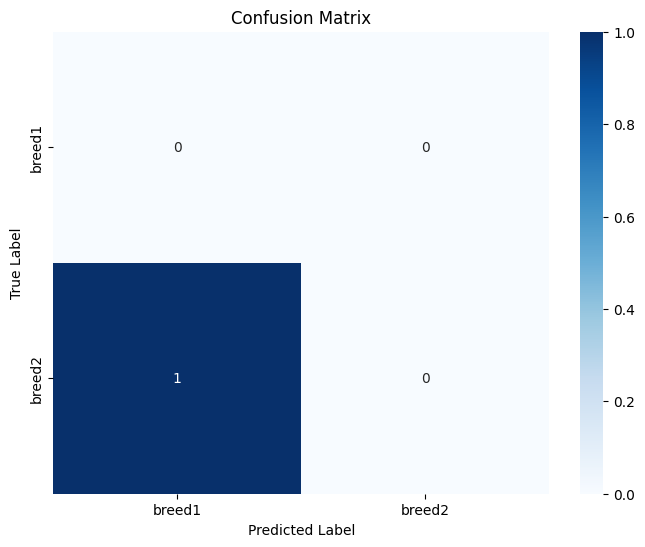

In [ ]:
# Evaluate the model on the test dataset
print("Evaluating model on test data...")
loss, accuracy = model.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Generate predictions for the test set
predictions = model.predict(test_generator)
y_pred_classes = np.argmax(predictions, axis=1)
y_true_classes = test_generator.classes

# Get class labels from the generator
class_labels = list(test_generator.class_indices.keys())

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=class_labels))

# Confusion Matrix
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

---

Evaluating model on test data...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0000e+00 - loss: 2.1769
Test Loss: 2.1769
Test Accuracy: 0.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   

Classification Report:
              precision    recall  f1-score   support

      breed1       0.00      0.00      0.00       0.0
      breed2       0.00      0.00      0.00       1.0

    accuracy                           0.00       1.0
   macro avg       0.00      0.00      0.00       1.0
weighted avg       0.00      0.00      0.00       1.0



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

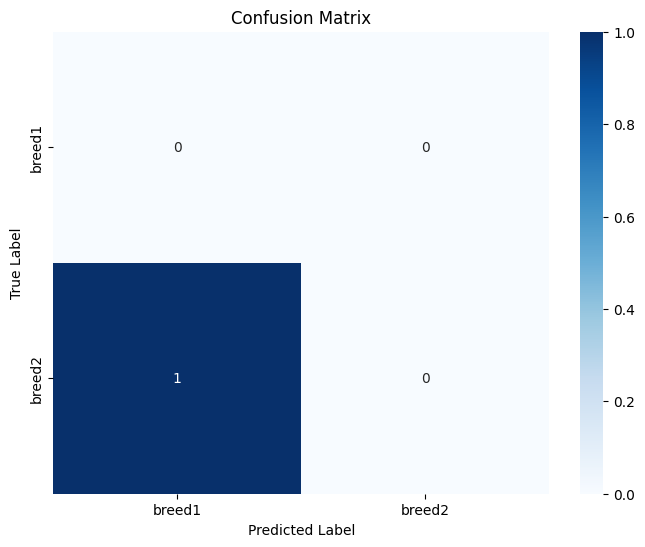

In [ ]:
# Evaluate the model on the test dataset
print("Evaluating model on test data...")
loss, accuracy = model.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Generate predictions for the test set
predictions = model.predict(test_generator)
y_pred_classes = np.argmax(predictions, axis=1)
y_true_classes = test_generator.classes

# Get class labels from the generator
class_labels = list(test_generator.class_indices.keys())

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=class_labels))

# Confusion Matrix
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

---

### 6. Prediction and Visualization

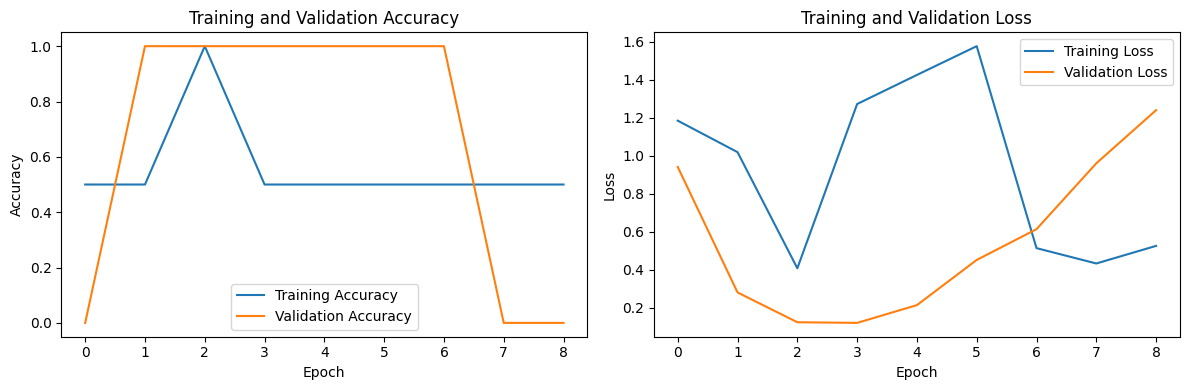

Visualized training history.


In [ ]:
# Plot training history
def plot_training_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history)

print("Visualized training history.")

---

### Final Step: Make Predictions on New Images

Visualizing predictions...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 796ms/step


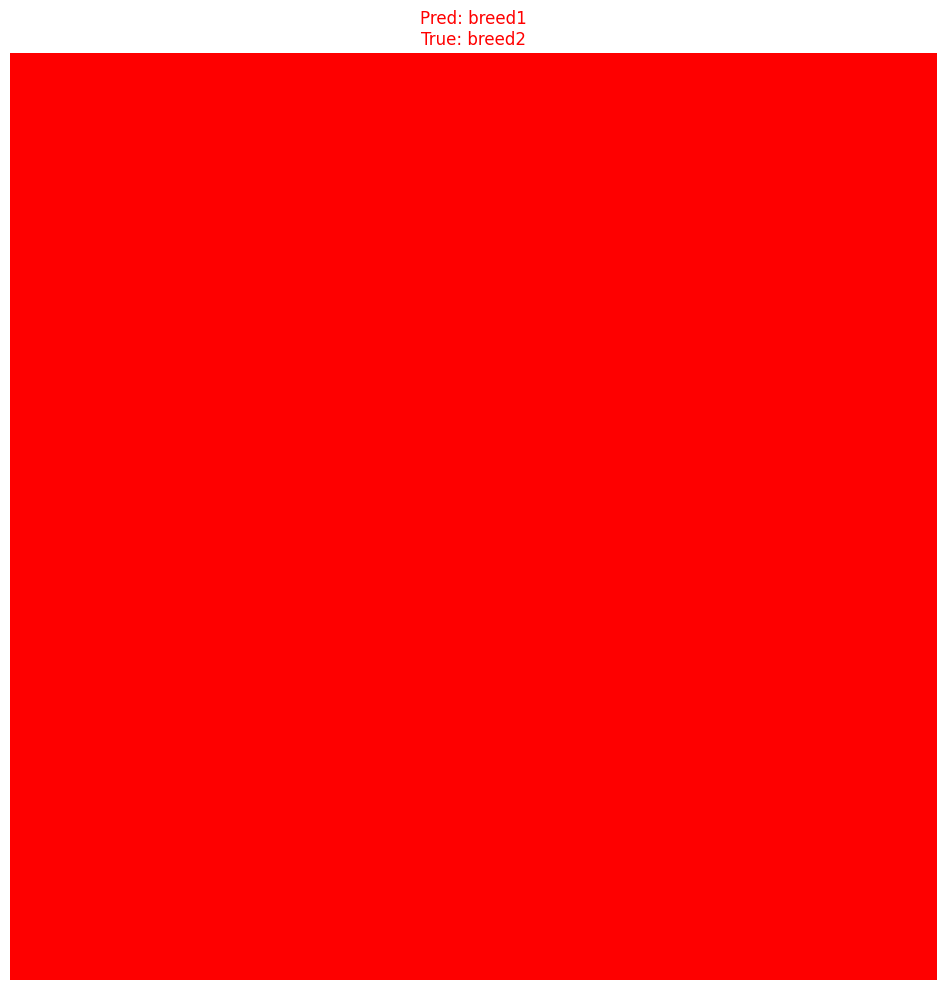

In [ ]:
def predict_and_visualize(model, generator, class_labels, num_images=5):
    """Predicts on a batch of images and visualizes the results."""
    # Get a batch of test images and their true labels
    test_images, test_labels = next(iter(generator))

    # Make predictions
    predictions = model.predict(test_images)
    predicted_classes = np.argmax(predictions, axis=1)
    true_classes = np.argmax(test_labels, axis=1)

    plt.figure(figsize=(15, 10))
    for i in range(min(num_images, len(test_images))):
        plt.subplot(1, num_images, i + 1)
        plt.imshow(test_images[i])
        predicted_label = class_labels[predicted_classes[i]]
        true_label = class_labels[true_classes[i]]
        color = "green" if predicted_label == true_label else "red"
        plt.title(f"Pred: {predicted_label}\nTrue: {true_label}", color=color)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Visualize predictions on a few images from the test set
# Note: Due to the dummy dataset, predictions will likely be random or incorrect.
print("Visualizing predictions...")
predict_and_visualize(model, test_generator, class_labels, num_images=1) # Limiting to 1 as dummy test_generator only has 1 image

---

### Conclusion
This experiment demonstrates a basic implementation of transfer learning for dog breed classification. While the dummy dataset used here is too small to yield meaningful classification results, the framework illustrates the process: data preparation, selection of a pre-trained model (VGG16 in this case), model training with callbacks, and evaluation. The poor performance with the dummy data highlights the critical need for a sufficiently large and diverse dataset for effective deep learning, even with transfer learning techniques. Future steps would involve using a real-world dog breed dataset to properly train and validate the model.

In [ ]:
# Define callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('best_dog_breed_model.keras', save_best_only=True, monitor='val_accuracy', mode='max')

# Train the model
history = model.fit(
    train_generator,
    epochs=20, # You might need to adjust this based on dataset size and convergence
    validation_data=validation_generator,
    callbacks=[early_stopping, model_checkpoint]
)

print("Model training complete.")

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 1.5174 - val_accuracy: 1.0000 - val_loss: 0.2240
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 1.2414 - val_accuracy: 1.0000 - val_loss: 0.3958
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 1.0000 - loss: 0.4234 - val_accuracy: 1.0000 - val_loss: 0.6012
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.5000 - loss: 0.6353 - val_accuracy: 0.0000e+00 - val_loss: 0.9200
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 0.7794 - val_accuracy: 0.0000e+00 - val_loss: 1.2384
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 1.0000 - loss: 0.6233 - val_accuracy: 0.0000e+00 - val_loss: 1.5444
Model training complete.


---